# 02 — Data Cleaning & Quality Checks

**IEEE-CIS Fraud Detection**

This notebook performs data quality analysis and applies cleaning rules:

1. Profile missingness across all columns
2. Analyze whether missingness itself is predictive of fraud
3. Inspect suspicious columns (D-columns, rare id columns)
4. Apply the **>50 % missing drop** rule from the project plan
5. Fix dtypes and standardise missing markers
6. Save the cleaned dataset to `data/interim/cleaned_train.parquet`

> **No modelling or splitting happens here.** Decisions are documented for reproducibility.

---
## 1 · Imports & Setup

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path.cwd().parent
RAW_DIR      = PROJECT_ROOT / "data" / "raw"
INTERIM_DIR  = PROJECT_ROOT / "data" / "interim"
FIG_DIR      = PROJECT_ROOT / "reports" / "figures"
TBL_DIR      = PROJECT_ROOT / "reports" / "tables"

for d in [INTERIM_DIR, FIG_DIR, TBL_DIR]:
    d.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 80)
pd.set_option("display.float_format", "{:.4f}".format)
sns.set_theme(style="whitegrid", palette="muted", font_scale=1.05)
%matplotlib inline

MISSING_THRESHOLD = 0.50  # drop columns above this fraction
TARGET = "isFraud"

print(f"Missing-drop threshold: {MISSING_THRESHOLD:.0%}")

Missing-drop threshold: 50%


---
## 2 · Load & Merge Raw Data

In [2]:
%%time
txn = pd.read_csv(RAW_DIR / "train_transaction.csv")
idn = pd.read_csv(RAW_DIR / "train_identity.csv")

df = txn.merge(idn, on="TransactionID", how="left")
del txn, idn

print(f"Merged shape: {df.shape[0]:,} rows × {df.shape[1]} columns")

Merged shape: 590,540 rows × 434 columns
CPU times: total: 10.2 s
Wall time: 10.8 s


---
## 3 · Missing-Value Profile

Compute the missingness percentage for every column and group them into tiers.

In [3]:
missing_frac = df.isna().mean().sort_values(ascending=False)
missing_pct  = (missing_frac * 100).round(2)

missing_table = pd.DataFrame({
    "missing_pct": missing_pct,
    "non_null": df.notna().sum(),
    "dtype": df.dtypes,
})

# Tier classification
def tier(pct):
    if pct == 0:    return "0%  (complete)"
    if pct <= 10:   return "0–10%  (low)"
    if pct <= 25:   return "10–25% (moderate)"
    if pct <= 50:   return "25–50% (high)"
    if pct <= 75:   return "50–75% (very high)"
    return "75–100% (extreme)"

missing_table["tier"] = missing_table["missing_pct"].apply(tier)

print("Missing-value tier summary:")
print(missing_table["tier"].value_counts().sort_index().to_string())
print(f"\nTotal columns: {len(missing_table)}")

Missing-value tier summary:
tier
0%  (complete)         52
0–10%  (low)           60
10–25% (moderate)      70
25–50% (high)          38
50–75% (very high)      6
75–100% (extreme)     208

Total columns: 434


In [4]:
# Columns above the drop threshold
cols_to_drop = missing_frac[missing_frac > MISSING_THRESHOLD].index.tolist()
cols_to_keep = missing_frac[missing_frac <= MISSING_THRESHOLD].index.tolist()

print(f"Columns above {MISSING_THRESHOLD:.0%} missing (will drop): {len(cols_to_drop)}")
print(f"Columns at or below threshold   (will keep): {len(cols_to_keep)}")

Columns above 50% missing (will drop): 214
Columns at or below threshold   (will keep): 220


In [5]:
# Save full missingness table
missing_table.to_csv(TBL_DIR / "missingness_all_columns.csv")
print(f"Saved → {TBL_DIR / 'missingness_all_columns.csv'}")

# Show the 30 worst columns
missing_table.head(30)

Saved → c:\Users\User\Documents\pfa\ieee_fraud_project\reports\tables\missingness_all_columns.csv


,missing_pct,non_null,dtype,tier
C1,0.0000,590540,float64,0% (complete)
C10,0.0000,590540,float64,0% (complete)
C11,0.0000,590540,float64,0% (complete)
C12,0.0000,590540,float64,0% (complete)
C13,0.0000,590540,float64,0% (complete)
C14,0.0000,590540,float64,0% (complete)
C2,0.0000,590540,float64,0% (complete)
C3,0.0000,590540,float64,0% (complete)
C4,0.0000,590540,float64,0% (complete)
C5,0.0000,590540,float64,0% (complete)


---
## 4 · Missing-Value Visualization

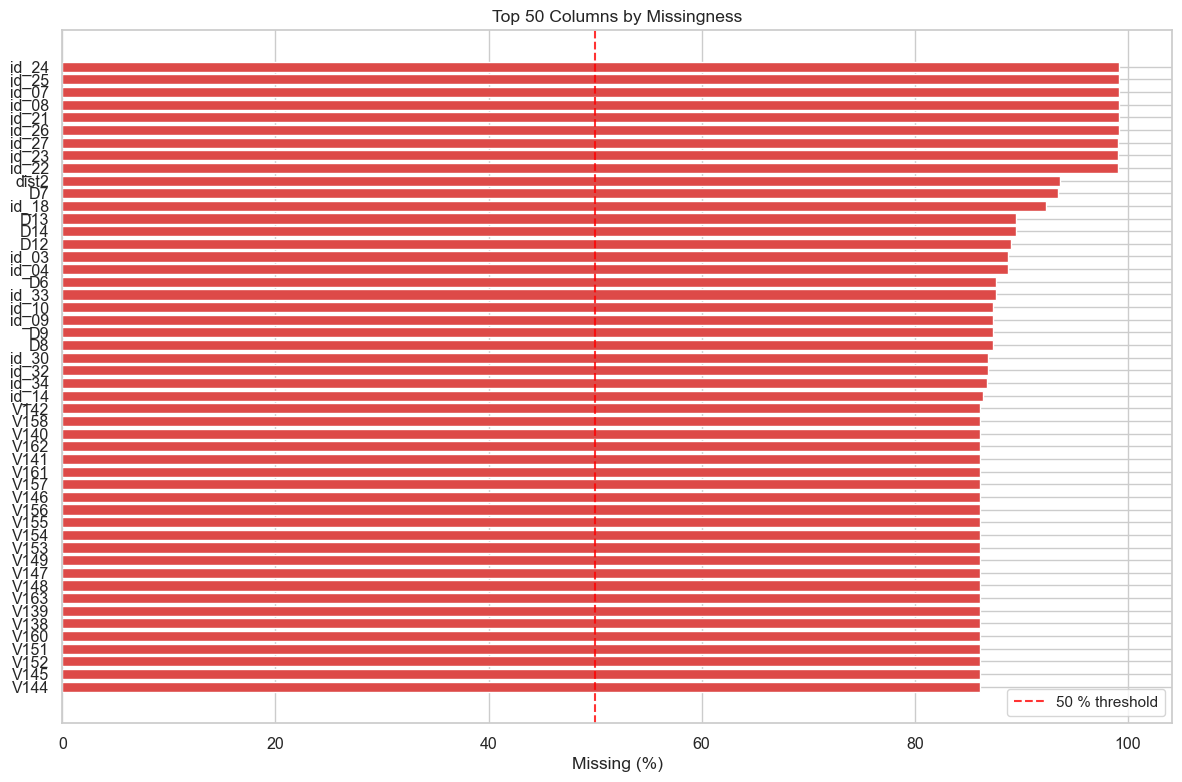

In [6]:
fig, ax = plt.subplots(figsize=(12, 8))

top_n = 50
top_missing = missing_pct.head(top_n)
colours = ["#DD4A48" if v > 50 else "#E8A838" if v > 25 else "#4C72B0" for v in top_missing.values]

ax.barh(top_missing.index[::-1], top_missing.values[::-1], color=colours[::-1], edgecolor="white")
ax.axvline(x=50, color="red", ls="--", lw=1.5, alpha=0.8, label="50 % threshold")
ax.set_xlabel("Missing (%)")
ax.set_title(f"Top {top_n} Columns by Missingness")
ax.legend(fontsize=11)

fig.tight_layout()
fig.savefig(FIG_DIR / "fig_missing_profile_top50.png", dpi=150, bbox_inches="tight")
plt.show()

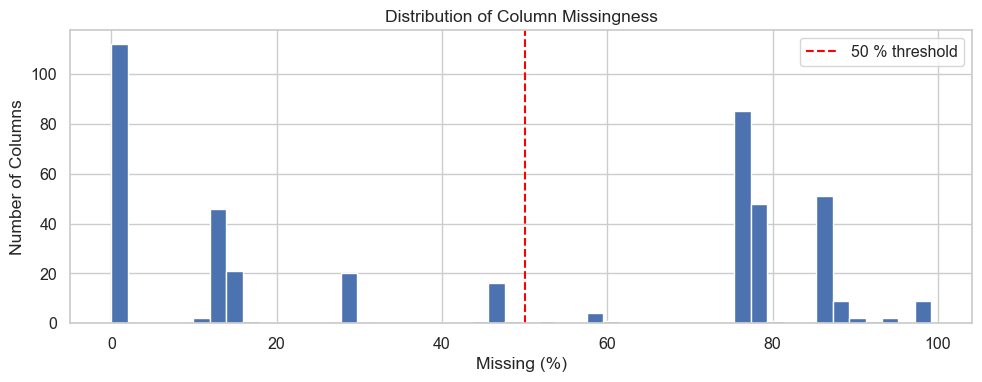

In [7]:
# Histogram of missingness percentages
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(missing_pct.values, bins=50, color="#4C72B0", edgecolor="white")
ax.axvline(x=50, color="red", ls="--", lw=1.5, label="50 % threshold")
ax.set_xlabel("Missing (%)")
ax.set_ylabel("Number of Columns")
ax.set_title("Distribution of Column Missingness")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "fig_missing_histogram.png", dpi=150, bbox_inches="tight")
plt.show()

> **Observation:** There is a clear cluster of columns with >75 % missingness (mostly `id_*` and some `V` columns).  
> The 50 % cut-off removes the worst offenders while keeping the bulk of usable features.

---
## 5 · Missingness as a Signal

Sometimes the *fact that a value is missing* is itself predictive of fraud.  
We compare the fraud rate when a column is present vs absent for selected columns.

In [8]:
# Columns with 10–80 % missing — where the signal is most interesting
signal_cols = missing_frac[(missing_frac > 0.10) & (missing_frac < 0.80)].index.tolist()

results = []
for col in signal_cols:
    present_rate = df.loc[df[col].notna(), TARGET].mean()
    missing_rate = df.loc[df[col].isna(), TARGET].mean()
    results.append({
        "column": col,
        "fraud_rate_present": round(present_rate * 100, 3),
        "fraud_rate_missing": round(missing_rate * 100, 3),
        "diff_pct_points": round((missing_rate - present_rate) * 100, 3),
        "missing_pct": round(missing_frac[col] * 100, 1),
    })

signal_df = pd.DataFrame(results).sort_values("diff_pct_points", ascending=False, key=abs)
signal_df.to_csv(TBL_DIR / "missingness_fraud_signal.csv", index=False)
print(f"Columns analysed: {len(signal_df)}")
signal_df.head(20)

Columns analysed: 248


,column,fraud_rate_present,fraud_rate_missing,diff_pct_points,missing_pct
247,addr2,2.4620,11.7810,9.3190,11.1000
246,addr1,2.4620,11.7810,9.3190,11.1000
1,id_13,8.3160,2.1750,-6.1410,78.4000
51,R_emaildomain,8.1780,2.0820,-6.0960,76.8000
50,id_06,8.0240,2.1340,-5.8900,76.8000
49,id_05,8.0240,2.1340,-5.8900,76.8000
107,id_02,7.9660,2.1000,-5.8670,76.1000
113,id_15,7.9600,2.1000,-5.8600,76.1000
112,id_36,7.9600,2.1000,-5.8600,76.1000
111,id_37,7.9600,2.1000,-5.8600,76.1000


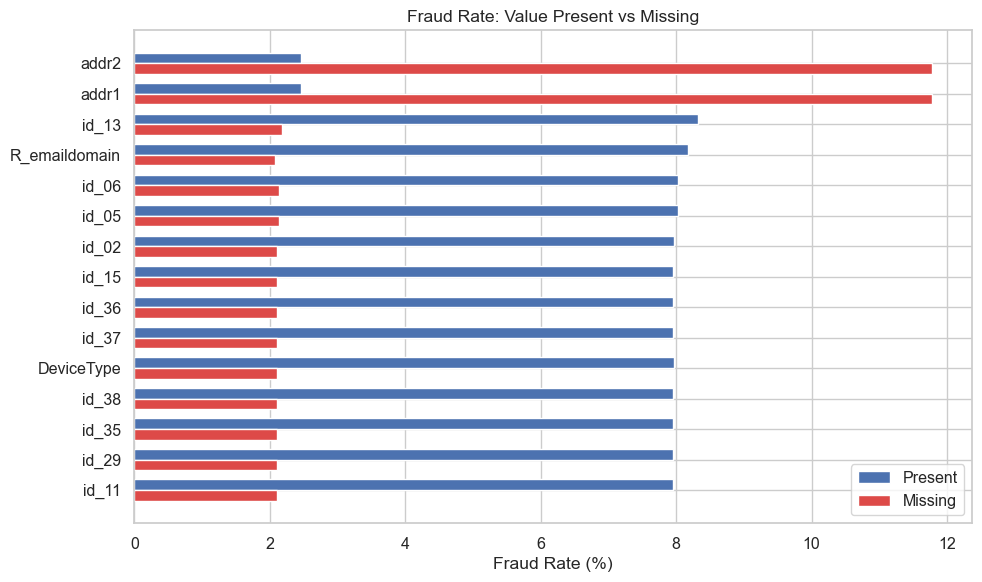

In [9]:
# Plot top 15 columns by missingness-signal strength
top_signal = signal_df.head(15)

fig, ax = plt.subplots(figsize=(10, 6))
x = np.arange(len(top_signal))
w = 0.35
ax.barh(x - w/2, top_signal["fraud_rate_present"], w, label="Present", color="#4C72B0")
ax.barh(x + w/2, top_signal["fraud_rate_missing"], w, label="Missing", color="#DD4A48")
ax.set_yticks(x)
ax.set_yticklabels(top_signal["column"])
ax.set_xlabel("Fraud Rate (%)")
ax.set_title("Fraud Rate: Value Present vs Missing")
ax.legend()
ax.invert_yaxis()
fig.tight_layout()
fig.savefig(FIG_DIR / "fig_missingness_fraud_signal.png", dpi=150, bbox_inches="tight")
plt.show()

> **Observation:** For several columns the fraud rate is *significantly* different when the value  
> is missing vs present. This means a binary `column_is_missing` flag could be a useful  
> feature during engineering (notebook 03). However, we do **not** create those flags now —  
> that belongs in the feature engineering step.

---
## 6 · Inspect Suspicious Columns

Some columns need special attention:  
- `dist1` / `dist2` — distance features, very sparse  
- `id_07`, `id_08` — almost empty identity columns  
- D-columns (`D1`–`D15`) — timedelta features with varied missingness

In [10]:
suspect_cols = ["dist1", "dist2", "id_07", "id_08", "D1", "D2", "D3", "D4", "D5",
                "D6", "D7", "D8", "D9", "D10", "D11", "D12", "D13", "D14", "D15"]
suspect_cols = [c for c in suspect_cols if c in df.columns]

suspect_summary = pd.DataFrame({
    "missing_%": (df[suspect_cols].isna().mean() * 100).round(1),
    "nunique": df[suspect_cols].nunique(),
    "min": df[suspect_cols].min(),
    "max": df[suspect_cols].max(),
    "median": df[suspect_cols].median(),
    "will_drop": [(missing_frac.get(c, 0) > MISSING_THRESHOLD) for c in suspect_cols],
})
suspect_summary

,missing_%,nunique,min,max,median,will_drop
dist1,59.7000,2651,0.0000,10286.0000,8.0000,True
dist2,93.6000,1751,0.0000,11623.0000,37.0000,True
id_07,99.1000,84,-46.0000,61.0000,14.0000,True
id_08,99.1000,94,-100.0000,0.0000,-34.0000,True
D1,0.2000,641,0.0000,640.0000,3.0000,False
D2,47.5000,641,0.0000,640.0000,97.0000,False
D3,44.5000,649,0.0000,819.0000,8.0000,False
D4,28.6000,808,-122.0000,869.0000,26.0000,False
D5,52.5000,688,0.0000,819.0000,10.0000,True
D6,87.6000,829,-83.0000,873.0000,0.0000,True


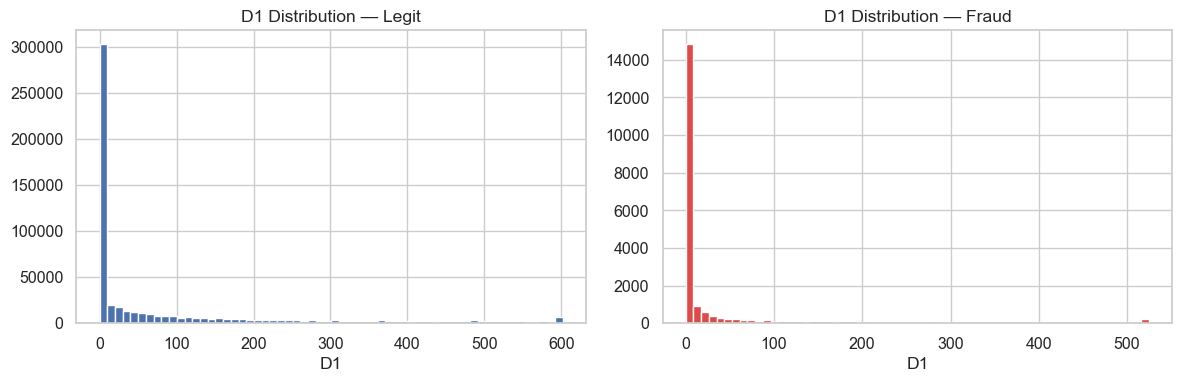

In [11]:
# D1 is important — check its relationship with fraud
if "D1" in df.columns and missing_frac.get("D1", 1) <= MISSING_THRESHOLD:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    
    for i, label in enumerate(["Legit", "Fraud"]):
        subset = df[df[TARGET] == i]["D1"].dropna()
        axes[i].hist(subset.clip(upper=subset.quantile(0.99)), bins=60,
                     color="#4C72B0" if i == 0 else "#DD4A48", edgecolor="white")
        axes[i].set_title(f"D1 Distribution — {label}")
        axes[i].set_xlabel("D1")
    fig.tight_layout()
    fig.savefig(FIG_DIR / "fig_D1_by_fraud.png", dpi=150, bbox_inches="tight")
    plt.show()

> **Observation:** `D1` (likely "days since last activity") has a different distribution for  
> fraud vs legit — it is a strong candidate feature. Columns like `dist2`, `id_07`, `id_08`  
> are extremely sparse and will be dropped by the 50 % rule.

---
## 7 · Standardise Missing-Value Markers

Some object columns contain placeholder strings ("NotFound", empty strings, etc.)  
that should be treated as true NaN.

In [12]:
placeholders = ["NotFound", "not_found", "", " ", "NA", "nan", "None"]

obj_cols = df.select_dtypes(include="object").columns
replacements = 0
for col in obj_cols:
    mask = df[col].isin(placeholders)
    n = mask.sum()
    if n > 0:
        df.loc[mask, col] = np.nan
        replacements += n

print(f"Replaced {replacements:,} placeholder values with NaN across {len(obj_cols)} object columns.")

Replaced 252,107 placeholder values with NaN across 31 object columns.


---
## 8 · Apply the >50 % Missing Drop Rule

**Policy:** Drop all columns whose missing fraction exceeds 50 %, *except*  
protected columns (`TransactionID`, `isFraud`, `TransactionDT`, `TransactionAmt`).

In [13]:
PROTECTED = {"TransactionID", "isFraud", "TransactionDT", "TransactionAmt"}

# Recompute after placeholder standardisation
missing_frac_updated = df.isna().mean()
drop_cols = [
    c for c in df.columns
    if missing_frac_updated[c] > MISSING_THRESHOLD and c not in PROTECTED
]

print(f"Columns to drop (>{MISSING_THRESHOLD:.0%} missing): {len(drop_cols)}")
print(f"Columns before: {len(df.columns)}")

df_cleaned = df.drop(columns=drop_cols)

print(f"Columns after : {len(df_cleaned.columns)}")
print(f"Rows          : {len(df_cleaned):,}  (unchanged)")

Columns to drop (>50% missing): 214
Columns before: 434
Columns after : 220
Rows          : 590,540  (unchanged)


In [14]:
# Save dropped-column list for reference
drop_df = pd.DataFrame({"column": drop_cols, "missing_pct": [round(missing_frac_updated[c]*100,1) for c in drop_cols]})
drop_df = drop_df.sort_values("missing_pct", ascending=False)
drop_df.to_csv(TBL_DIR / "dropped_columns.csv", index=False)
print(f"Saved dropped-column list → {TBL_DIR / 'dropped_columns.csv'}")
drop_df.head(20)

Saved dropped-column list → c:\Users\User\Documents\pfa\ieee_fraud_project\reports\tables\dropped_columns.csv


,column,missing_pct
197,id_24,99.2000
198,id_25,99.1000
195,id_22,99.1000
180,id_07,99.1000
181,id_08,99.1000
200,id_27,99.1000
194,id_21,99.1000
196,id_23,99.1000
199,id_26,99.1000
185,id_12,96.4000


---
## 9 · Dtype Cleanup

Cast known categorical columns to `category` dtype to save memory  
and help downstream code distinguish categorical from numeric.

In [15]:
known_cat_cols = [
    "ProductCD", "card4", "card6",
    "P_emaildomain", "R_emaildomain",
    "M1", "M2", "M3", "M4", "M5", "M6", "M7", "M8", "M9",
    "DeviceType", "DeviceInfo",
]
# Only cast columns that survived the drop
for col in known_cat_cols:
    if col in df_cleaned.columns:
        df_cleaned[col] = df_cleaned[col].astype("category")

print("Dtype breakdown after cleanup:")
print(df_cleaned.dtypes.value_counts().to_string())

Dtype breakdown after cleanup:
float64     207
int64         4
category      4
category      1
category      1
category      1
category      1
category      1


---
## 10 · Post-Cleaning Sanity Checks

In [16]:
# Target still present?
assert TARGET in df_cleaned.columns, "Target column was dropped!"
print(f"✓ Target '{TARGET}' present")

# Target still binary?
assert set(df_cleaned[TARGET].unique()) == {0, 1}
print(f"✓ Target is binary: {sorted(df_cleaned[TARGET].unique())}")

# TransactionID still unique?
assert df_cleaned["TransactionID"].is_unique
print(f"✓ TransactionID is unique")

# Row count unchanged?
assert len(df_cleaned) == len(df)
print(f"✓ Row count unchanged: {len(df_cleaned):,}")

# Remaining missingness profile
remaining_missing = (df_cleaned.isna().mean() * 100).describe()
print(f"\nRemaining missingness stats (%):\n{remaining_missing.round(2).to_string()}")

✓ Target 'isFraud' present
✓ Target is binary: [0, 1]
✓ TransactionID is unique
✓ Row count unchanged: 590,540

Remaining missingness stats (%):
count   220.0000
mean     10.8000
std      14.0800
min       0.0000
25%       0.0500
50%       0.4900
75%      15.1000
max      47.6600


In [17]:
print(f"\nMemory before cleaning: {df.memory_usage(deep=True).sum() / 1e6:.1f} MB")
print(f"Memory after cleaning : {df_cleaned.memory_usage(deep=True).sum() / 1e6:.1f} MB")


Memory before cleaning: 2683.5 MB
Memory after cleaning : 1002.2 MB


---
## 11 · Save Cleaned Dataset

In [18]:
output_path = INTERIM_DIR / "cleaned_train.parquet"
df_cleaned.to_parquet(output_path, index=False, engine="pyarrow")
print(f"Saved cleaned dataset → {output_path}")
print(f"  Shape: {df_cleaned.shape}")
print(f"  Size : {output_path.stat().st_size / 1e6:.1f} MB")

Saved cleaned dataset → c:\Users\User\Documents\pfa\ieee_fraud_project\data\interim\cleaned_train.parquet
  Shape: (590540, 220)
  Size : 55.1 MB


---
## 12 · Summary of Cleaning Decisions

| Decision | Detail |
|----------|--------|
| **Columns dropped** | All columns with > 50 % missing values |
| **Protected columns** | `TransactionID`, `isFraud`, `TransactionDT`, `TransactionAmt` never dropped |
| **Placeholder cleanup** | Strings like `"NotFound"`, `""`, `" "` replaced with `NaN` |
| **Dtype casting** | Known categoricals cast to `category` dtype |
| **Imputation** | **Not done yet** — imputers will be fit on training data only after the split |
| **Row count** | Unchanged — no rows were removed |

### Why not impute now?

Imputation statistics (median, mode) must be computed on the **training fold only**.  
If we imputed here (before splitting), the validation and test sets would contain  
information from the full dataset → **leakage**.  
Imputation will happen in the training pipeline (notebook 05 / `src/preprocessing`).

### Next notebook

→ **`03_feature_engineering.ipynb`** — design and test fraud-related features.

In [19]:
print("Notebook 02 complete. ✓")

Notebook 02 complete. ✓
